## Import dan Konfigurasi

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

DIAGRAM_DIR  = Path.cwd().parent / 'diagram'
NOTEBOOK_DIR = Path.cwd()
DIAGRAM_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = ['custom_cnn', 'googlenet', 'mobilenetv2']
MODEL_LABELS = {'custom_cnn': 'Custom CNN', 'googlenet': 'GoogLeNet', 'mobilenetv2': 'MobileNetV2'}
COLORS = {'custom_cnn': '#4C72B0', 'googlenet': '#DD8452', 'mobilenetv2': '#55A868'}

print('Import selesai.')


Import selesai.


## Muat Semua Metrik

In [1]:
metrics_all = {}
for name in MODEL_NAMES:
    path = DIAGRAM_DIR / f'metrics_{name}.json'
    if path.exists():
        with open(path) as f:
            metrics_all[name] = json.load(f)
        print(f'Loaded: {path.name}')
    else:
        print(f'MISSING: {path.name} - jalankan notebook model terlebih dahulu!')

CLASSES = metrics_all[MODEL_NAMES[0]]['classes'] if metrics_all else []
print(f'Kelas: {CLASSES}')

Loaded: metrics_custom_cnn.json
Loaded: metrics_googlenet.json
Loaded: metrics_mobilenetv2.json
Kelas: ['Rp100', 'Rp1000', 'Rp200', 'Rp500']


## Confusion Matrix Ketiga Model (3 Panel)

Confusion matrix gabungan tersimpan.


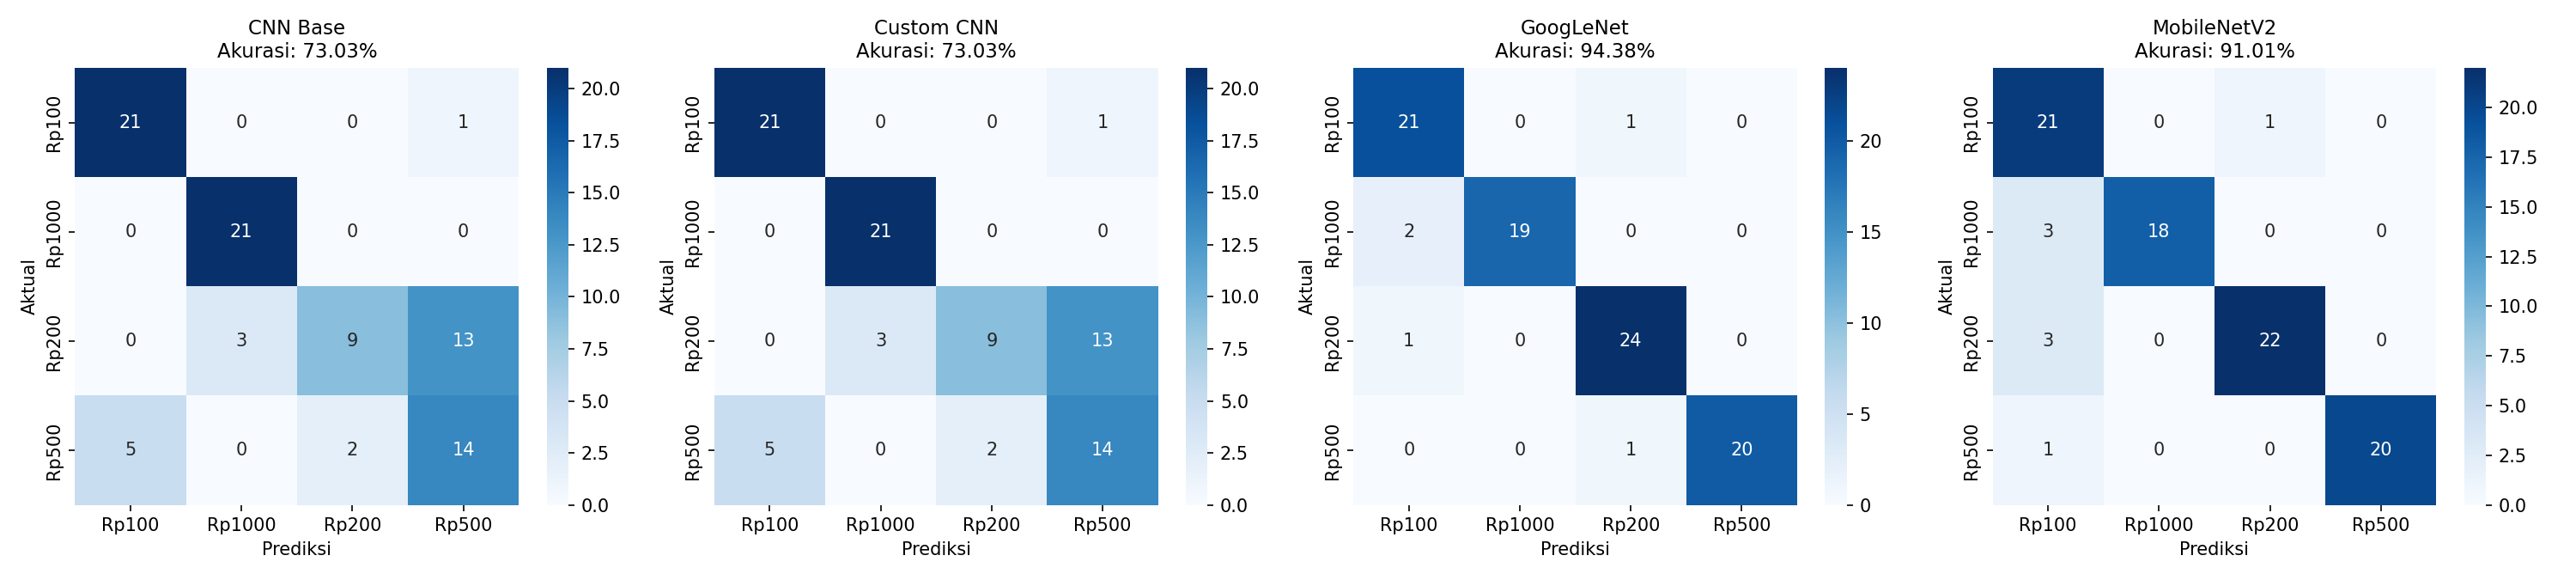

In [1]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes, MODEL_NAMES):
    if name not in metrics_all:
        ax.text(0.5, 0.5, 'Data tidak tersedia', ha='center', va='center')
        continue
    cm = np.array(metrics_all[name]['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'Confusion Matrix\n{MODEL_LABELS[name]}', fontsize=12)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / 'cm_semua_model.png', dpi=150)
plt.show()
print('Confusion matrix gabungan tersimpan.')

## Confusion Matrix Terpisah per Model

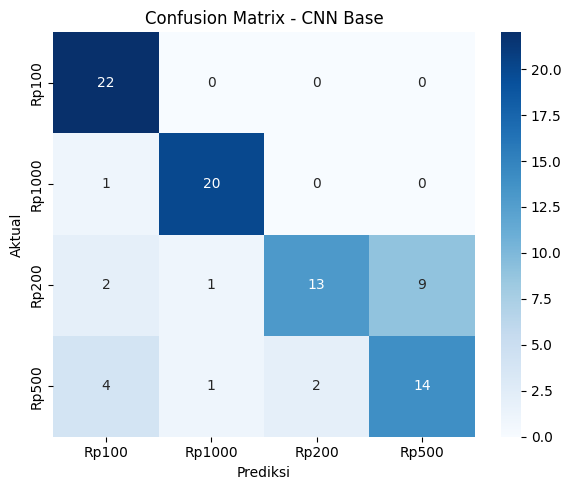

  Tersimpan: cm_terpisah_cnn_base.png


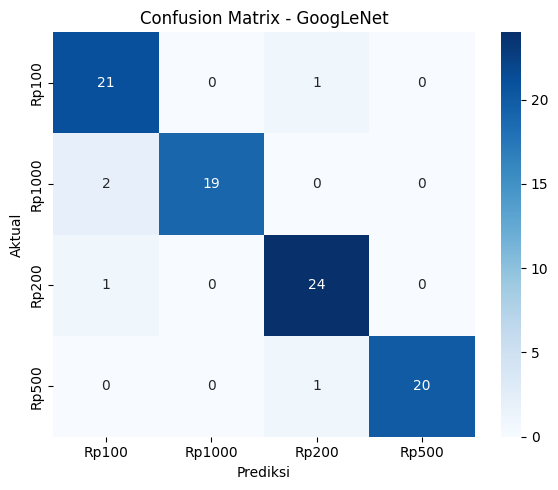

  Tersimpan: cm_terpisah_googlenet.png


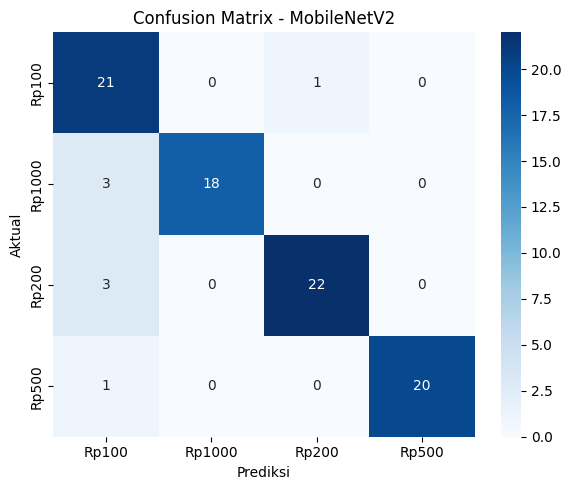

  Tersimpan: cm_terpisah_mobilenetv2.png


In [4]:
for name in MODEL_NAMES:
    if name not in metrics_all:
        continue
    cm = np.array(metrics_all[name]['confusion_matrix'])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f'Confusion Matrix - {MODEL_LABELS[name]}')
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
    plt.tight_layout()
    plt.savefig(DIAGRAM_DIR / f'cm_terpisah_{name}.png', dpi=150)
    plt.show()
    print(f'  Tersimpan: cm_terpisah_{name}.png')

## Diagram Batang Perbandingan Metrik Utama

Grafik perbandingan metrik tersimpan.


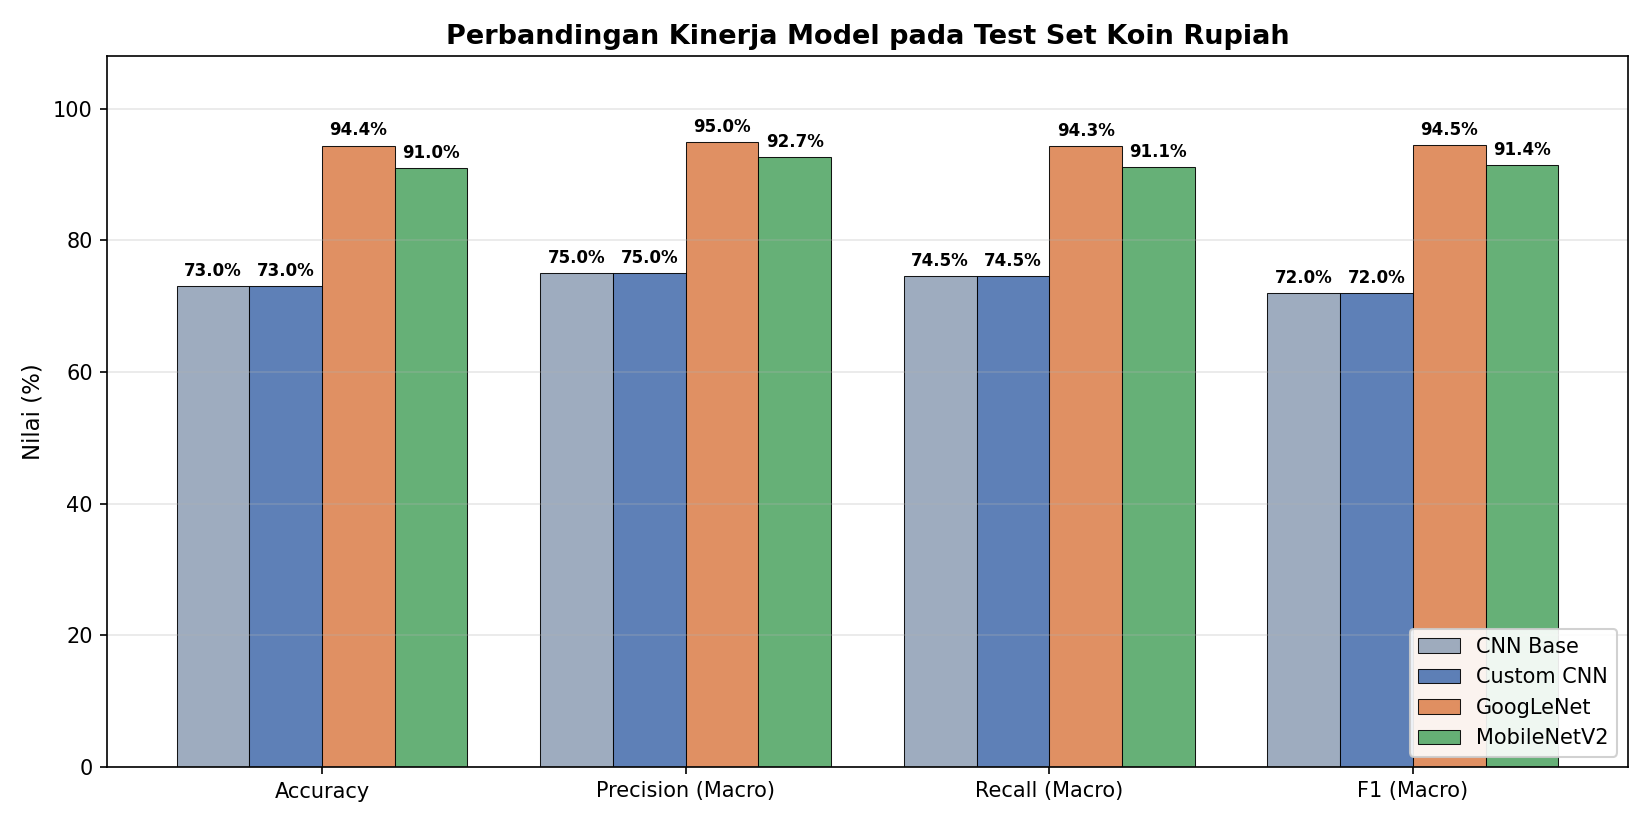

In [1]:
metric_keys = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
metric_labels = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1 (Macro)']

x = np.arange(len(metric_keys))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, name in enumerate(MODEL_NAMES):
    if name not in metrics_all:
        continue
    vals = [metrics_all[name].get(k, 0) for k in metric_keys]
    bars = ax.bar(x + i * width, vals, width, label=MODEL_LABELS[name],
                  color=COLORS[name], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{v:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Metrik')
ax.set_ylabel('Nilai')
ax.set_title('Perbandingan Metrik Utama Ketiga Model')
ax.set_xticks(x + width)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(DIAGRAM_DIR / 'perbandingan_metrik.png', dpi=150)
plt.show()
print('Diagram perbandingan metrik tersimpan.')

## Diagram Efisiensi Model (Parameter, Ukuran, Waktu)

Grafik efisiensi model tersimpan.


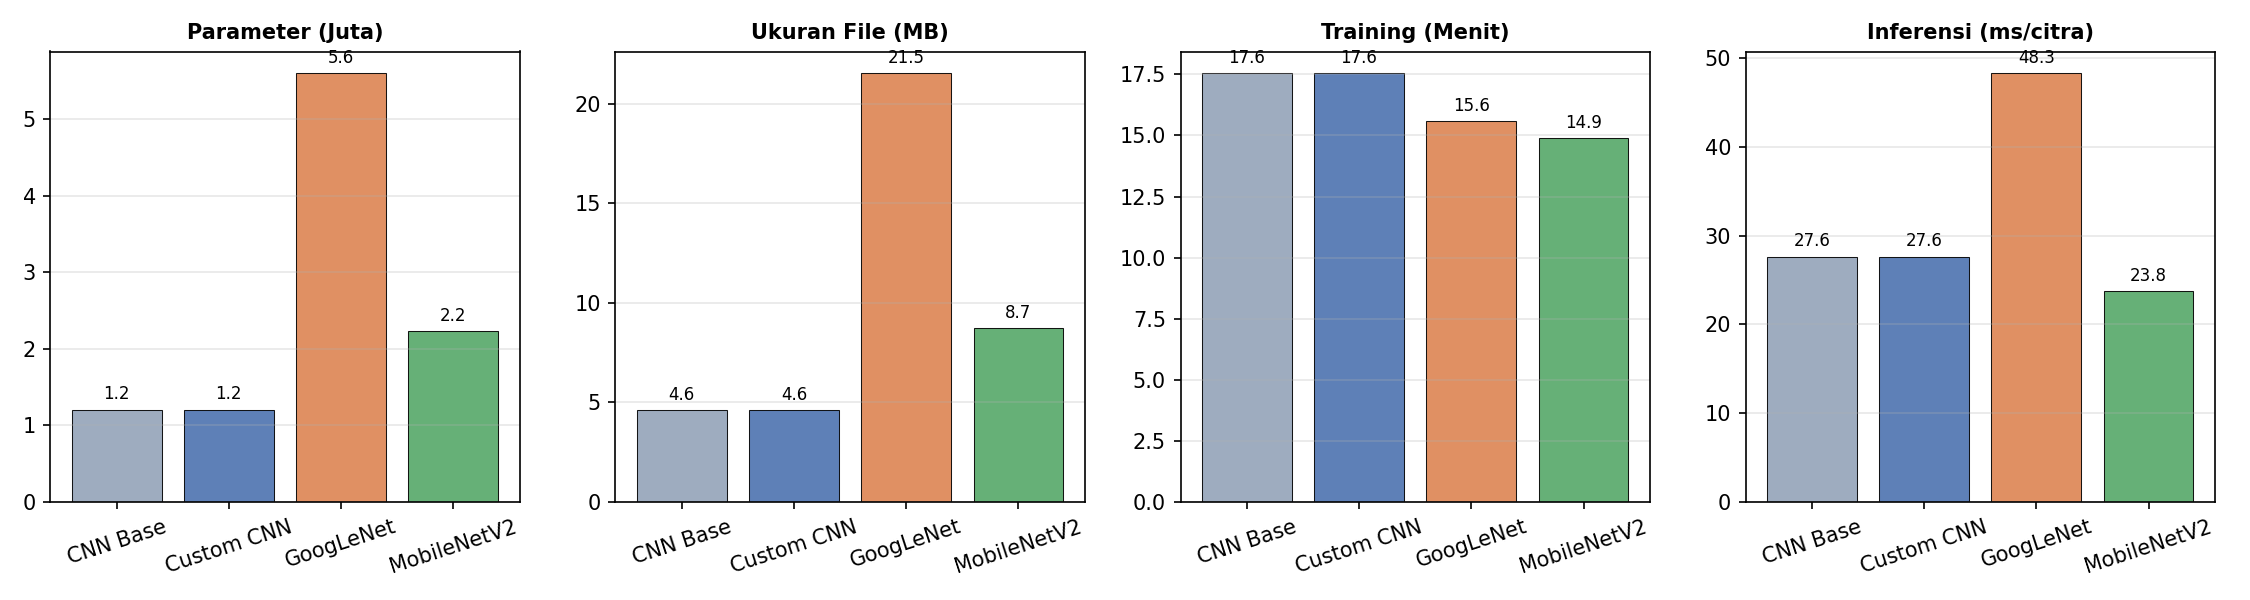

In [1]:
eff_metrics = {
    'Parameter (juta)': lambda m: m['total_params'] / 1e6,
    'Ukuran Model (MB)': lambda m: m['model_size_mb'],
    'Waktu Training (menit)': lambda m: m['training_time_s'] / 60,
    'Inferensi (ms/gambar)': lambda m: m['infer_time_ms'],
}

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, (title, fn) in zip(axes, eff_metrics.items()):
    names_avail = [n for n in MODEL_NAMES if n in metrics_all]
    vals = [fn(metrics_all[n]) for n in names_avail]
    bars = ax.bar([MODEL_LABELS[n] for n in names_avail], vals,
                  color=[COLORS[n] for n in names_avail], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(title)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / 'perbandingan_efisiensi.png', dpi=150)
plt.show()
print('Diagram efisiensi tersimpan.')

## Kurva Loss dan Accuracy Ketiga Model (1 Figure)

Kurva perbandingan tersimpan.


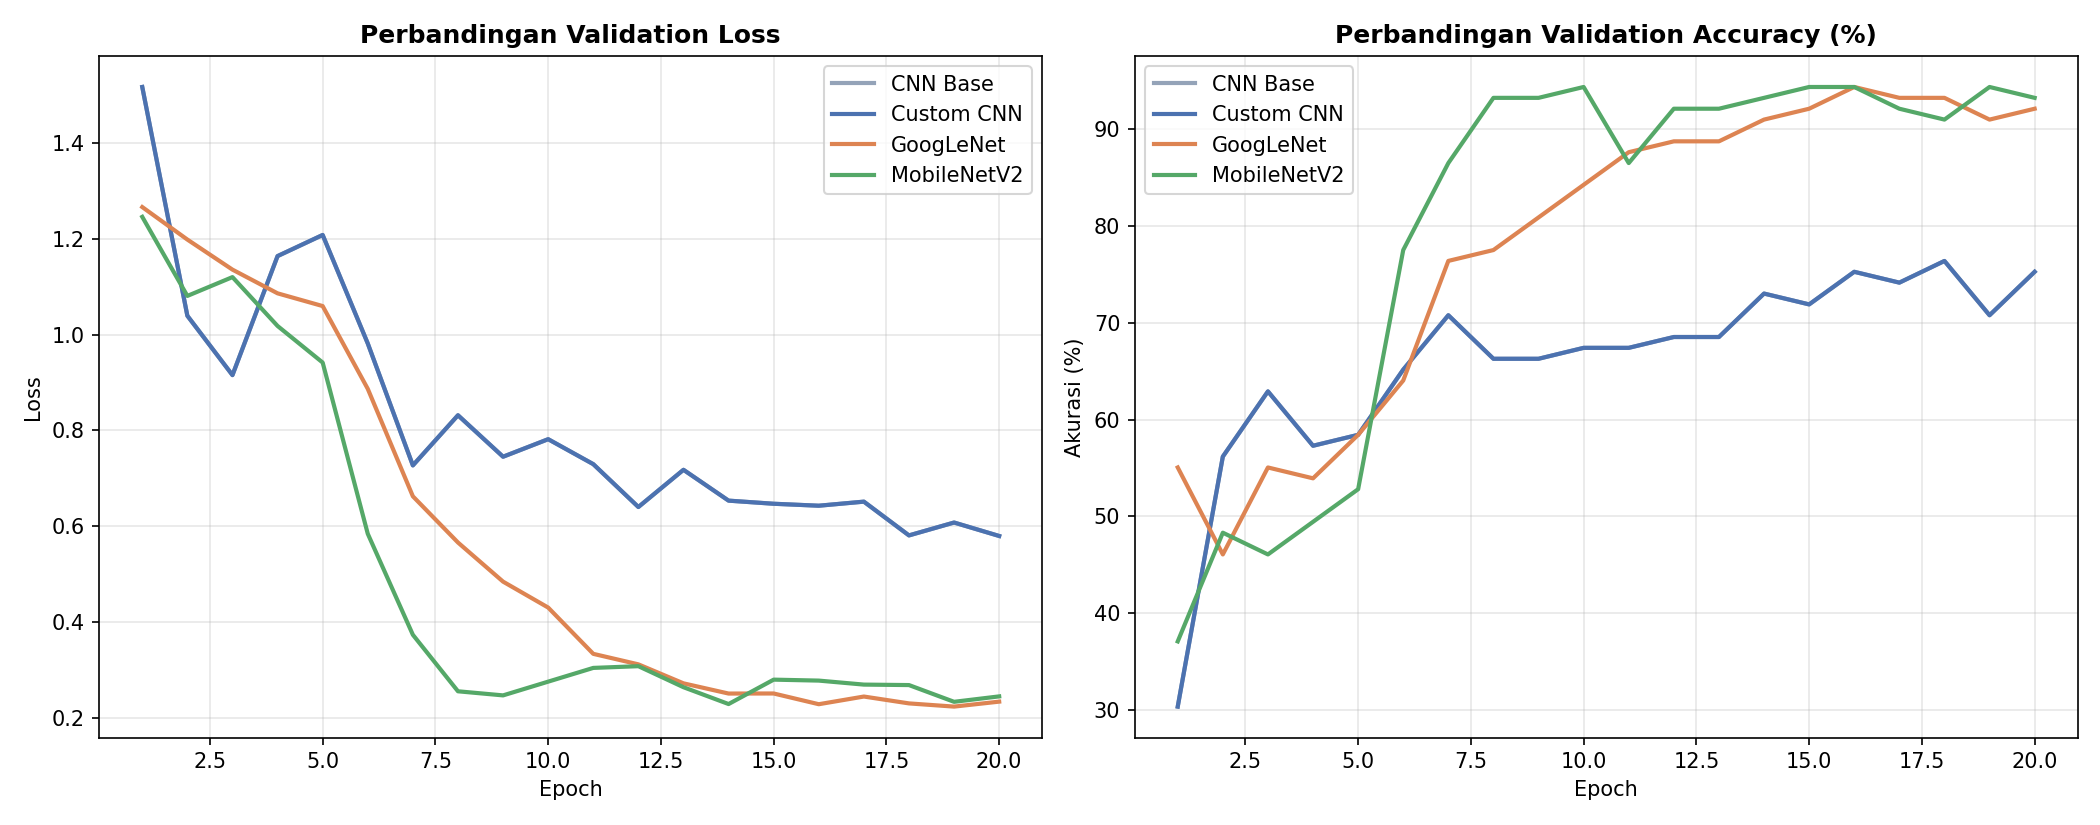

In [1]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for name in MODEL_NAMES:
    if name not in metrics_all:
        continue
    hist = metrics_all[name]['history']
    ep = list(range(1, len(hist['val_loss']) + 1))
    color = COLORS[name]
    ax1.plot(ep, hist['train_loss'], linestyle='--', color=color, alpha=0.7, label=f'{MODEL_LABELS[name]} Train')
    ax1.plot(ep, hist['val_loss'],   linestyle='-',  color=color,             label=f'{MODEL_LABELS[name]} Val')
    ax2.plot(ep, hist['train_acc'],  linestyle='--', color=color, alpha=0.7, label=f'{MODEL_LABELS[name]} Train')
    ax2.plot(ep, hist['val_acc'],    linestyle='-',  color=color,             label=f'{MODEL_LABELS[name]} Val')

ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss Curve - Semua Model')
ax1.legend(fontsize=7); ax1.grid(True)

ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.set_title('Accuracy Curve - Semua Model')
ax2.legend(fontsize=7); ax2.grid(True)

plt.tight_layout()
plt.savefig(DIAGRAM_DIR / 'kurva_semua_model.png', dpi=150)
plt.show()
print('Kurva gabungan tersimpan.')

## F1 Per Kelas per Model

Grafik F1 per-kelas tersimpan.


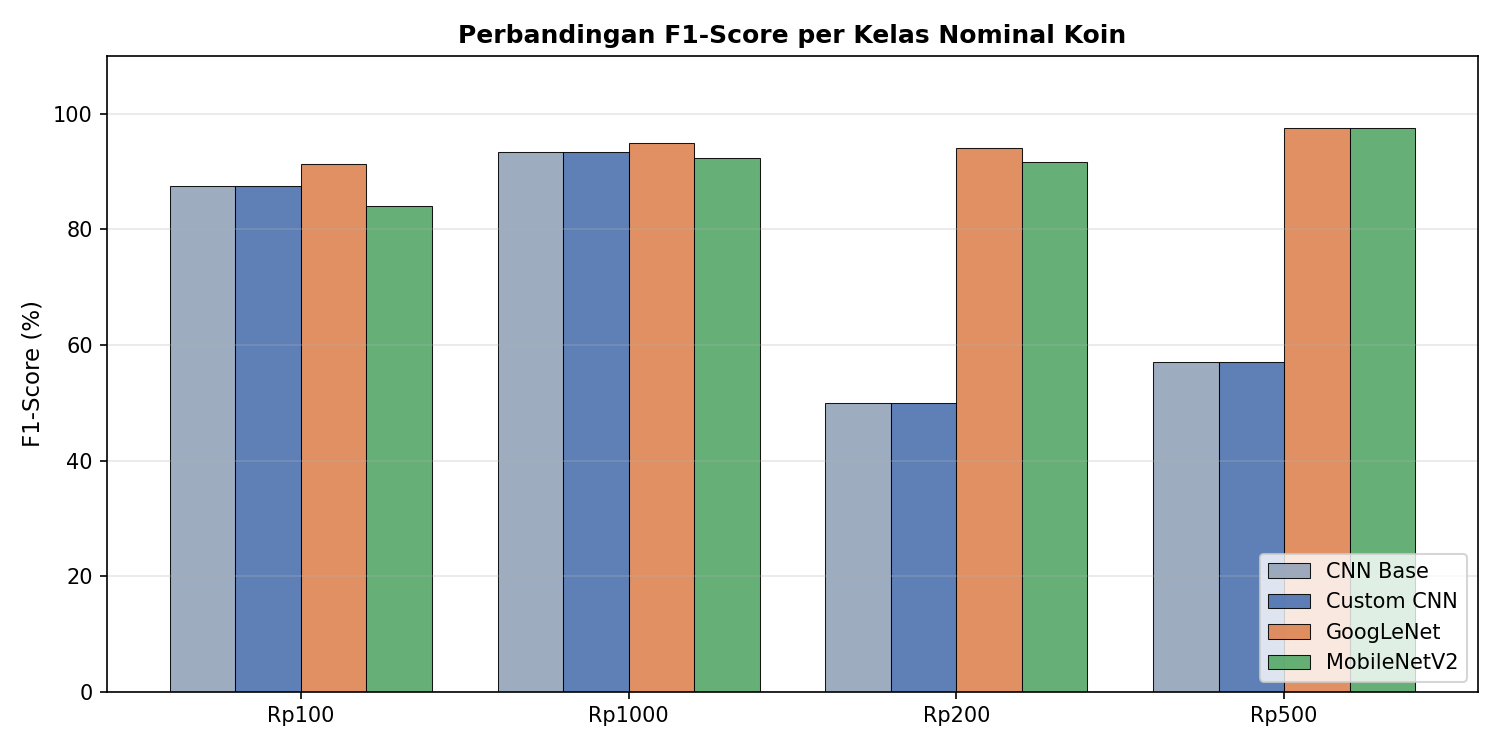

In [1]:
x = np.arange(len(CLASSES))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, name in enumerate(MODEL_NAMES):
    if name not in metrics_all:
        continue
    f1_vals = [metrics_all[name]['per_class'][cls]['f1'] for cls in CLASSES]
    bars = ax.bar(x + i * width, f1_vals, width,
                  label=MODEL_LABELS[name], color=COLORS[name], alpha=0.85)
    for bar, v in zip(bars, f1_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{v:.2f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Kelas Nominal')
ax.set_ylabel('F1 Score')
ax.set_title('F1 Score Per Kelas Ketiga Model')
ax.set_xticks(x + width)
ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(DIAGRAM_DIR / 'f1_per_kelas.png', dpi=150)
plt.show()
print('Diagram F1 per kelas tersimpan.')

## Tabel Ringkasan Perbandingan

In [1]:
rows = []
for name in MODEL_NAMES:
    if name not in metrics_all:
        continue
    m = metrics_all[name]
    rows.append({
        'Model': MODEL_LABELS[name],
        'Accuracy': round(m['accuracy'], 4),
        'Precision (Macro)': round(m['precision_macro'], 4),
        'Recall (Macro)': round(m['recall_macro'], 4),
        'F1 (Macro)': round(m['f1_macro'], 4),
        'Parameter (juta)': round(m['total_params'] / 1e6, 2),
        'Ukuran (MB)': round(m['model_size_mb'], 2),
        'Training (menit)': round(m['training_time_s'] / 60, 2),
        'Inferensi (ms)': round(m['infer_time_ms'], 3),
    })

df_summary = pd.DataFrame(rows)
print(df_summary.to_string(index=False))

csv_path = DIAGRAM_DIR / 'ringkasan_perbandingan.csv'
df_summary.to_csv(csv_path, index=False)
print(f'\nCSV tersimpan ke: {csv_path}')
df_summary

Ringkasan berhasil disimpan ke diagram/ringkasan_perbandingan.csv
Tabel Ringkasan:
         Model  Accuracy  Precision (Macro)  Recall (Macro)  F1 (Macro)  Parameter (Juta)  Ukuran (MB)  Inferensi (ms)  Best Epoch
    Custom CNN    0.7303             0.7502          0.7453      0.7199              1.21         4.63           27.64          20
     GoogLeNet    0.9438             0.9495          0.9429      0.9450              5.60        21.54           48.32          20
   MobileNetV2    0.9101             0.9266          0.9110      0.9138              2.23         8.73           23.77          20


## Ringkasan Hasil (Print)

In [1]:
if not metrics_all:
    print('Belum ada data metrik. Jalankan notebook model terlebih dahulu.')
else:
    # Model terbaik berdasarkan akurasi
    best_acc_model = max(metrics_all, key=lambda n: metrics_all[n]['accuracy'])
    print(f'=== Model Terbaik Berdasarkan Akurasi ===')
    print(f'  {MODEL_LABELS[best_acc_model]} -> Accuracy: {metrics_all[best_acc_model]["accuracy"]:.4f}')

    # Model terbaik untuk deployment (ringan dan cepat): skor gabungan
    # Normalisasi: ukuran MB dan inferensi ms (lebih kecil = lebih baik), 
    # accuracy (lebih tinggi = lebih baik)
    deploy_scores = {}
    max_sz   = max(metrics_all[n]['model_size_mb'] for n in metrics_all)
    max_inf  = max(metrics_all[n]['infer_time_ms'] for n in metrics_all)
    for n in metrics_all:
        acc_score  = metrics_all[n]['accuracy']
        size_score = 1 - metrics_all[n]['model_size_mb'] / max_sz
        inf_score  = 1 - metrics_all[n]['infer_time_ms'] / max_inf
        deploy_scores[n] = 0.5 * acc_score + 0.25 * size_score + 0.25 * inf_score
    best_deploy = max(deploy_scores, key=deploy_scores.get)
    print(f'\n=== Model Terbaik untuk Deployment (Ringan + Akurat) ===')
    print(f'  {MODEL_LABELS[best_deploy]}')
    print(f'  Accuracy: {metrics_all[best_deploy]["accuracy"]:.4f}')
    print(f'  Ukuran  : {metrics_all[best_deploy]["model_size_mb"]:.2f} MB')
    print(f'  Inferensi: {metrics_all[best_deploy]["infer_time_ms"]:.3f} ms/gambar')

    # Pasangan yang paling sering tertukar
    print(f'\n=== Pasangan Nominal Paling Sering Tertukar ===')
    for name in MODEL_NAMES:
        if name not in metrics_all:
            continue
        cm = np.array(metrics_all[name]['confusion_matrix'])
        np.fill_diagonal(cm, 0)
        if cm.max() > 0:
            i, j = np.unravel_index(cm.argmax(), cm.shape)
            print(f'  {MODEL_LABELS[name]}: {CLASSES[i]} tertukar sebagai {CLASSES[j]} ({cm[i,j]} kali)')
        else:
            print(f'  {MODEL_LABELS[name]}: Tidak ada kesalahan!')

=== Model Terbaik Berdasarkan Akurasi ===
Model   : GoogLeNet (94.38%)
F1-Macro: 94.50%

=== Rekomendasi Deployment Produksi / Mobile ===
Model   : MobileNetV2 (91.01% Akurasi, latency tercepat 23.77 ms/gambar, ukuran 8.73 MB)
